## 1. وارد کردن کتابخانه‌ها

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier
)

pd.set_option("display.max_columns", None)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. وارد کردن ابزارهای متعادل‌سازی و تنظیم هایپرپارامتر

In [2]:
# !pip install imbalanced-learn 
from imblearn.over_sampling import SMOTENC
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import roc_auc_score

## 3. خواندن دیتاست Give Me Some Credit

In [3]:
data = pd.read_csv("GiveMeSomeCredit.csv")

print("Dataset shape:", data.shape)

display(data.head())

Dataset shape: (149724, 14)


,SeriousDlqin,RevolvingUtilizationOfUnsecuredLines,age,SEX,EDUCATION,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,NumberOfDefault
0,1,0.878881,40,F,3,0,0.605616,12000.0,19,2,3,11,0.0,1
1,0,1.000000,34,F,1,3,2121.000000,0.0,9,0,2,9,2.0,0
2,0,0.470085,59,F,1,5,1.280078,15916.0,34,6,14,8,0.0,0
3,1,0.908082,26,M,3,3,1.444855,6500.0,22,1,4,8,0.0,2
4,1,1.000000,36,M,3,4,0.913676,2200.0,10,1,1,7,1.0,1


## 4. ساخت نسخه کپی از داده

In [4]:
df = data.copy()

print("Original shape:", data.shape)
print("Working dataframe shape:", df.shape)

Original shape: (149724, 14)
Working dataframe shape: (149724, 14)


## 5. بررسی ساختار و نوع ستون‌ها

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149724 entries, 0 to 149723
Data columns (total 14 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin                          149724 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  149724 non-null  float64
 2   age                                   149724 non-null  int64  
 3   SEX                                   149724 non-null  object 
 4   EDUCATION                             149724 non-null  int64  
 5   NumberOfTime30-59DaysPastDueNotWorse  149724 non-null  int64  
 6   DebtRatio                             149724 non-null  float64
 7   MonthlyIncome                         120117 non-null  float64
 8   NumberOfOpenCreditLinesAndLoans       149724 non-null  int64  
 9   NumberOfTimes90DaysLate               149724 non-null  int64  
 10  NumberRealEstateLoansOrLines          149724 non-null  int64  
 11  

## 6. بررسی مقادیر گمشده

In [6]:
missing_report = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percent": (
        df.isnull().mean() * 100
    ).round(2)
})

display(
    missing_report.sort_values(
        by="Missing_Percent",
        ascending=False
    )
)

,Missing_Count,Missing_Percent
MonthlyIncome,29607,19.77
NumberOfDependents,3893,2.60
SeriousDlqin,0,0.00
RevolvingUtilizationOfUnsecuredLines,0,0.00
age,0,0.00
SEX,0,0.00
EDUCATION,0,0.00
NumberOfTime30-59DaysPastDueNotWorse,0,0.00
DebtRatio,0,0.00
NumberOfOpenCreditLinesAndLoans,0,0.00



ستون MonthlyIncome با ۲۹٬۶۰۷ مقدار گمشده (۱۹.۷۷٪) و NumberOfDependents با ۳٬۸۹۳ مقدار گمشده (۲.۶٪) تنها ستون‌های دارای مقدار گمشده‌اند.
چون درصد گمشدگی درآمد بالاست، علاوه بر جایگزینی، ستون نشانگر گمشدگی هم برای آن می‌سازیم.

## 7. بررسی نشت اطلاعات (Target Leakage)


In [7]:
target = "SeriousDlqin"

print(
    pd.crosstab(
        df["NumberOfDefault"],
        df[target]
    )
)

SeriousDlqin          0     1
NumberOfDefault              
0                139845     0
1                     0  3260
2                     0  3258
3                     0  3361



ستون NumberOfDefault برای همه مشتریان خوش‌حساب برابر ۰ و برای همه مشتریان بدحساب برابر ۱ تا ۳ است، یعنی مستقیماً از روی برچسب ساخته شده.
استفاده از آن باعث Target Leakage و نتایج غیرواقعی می‌شود، پس باید حذف شود.

## 8. حذف ستون NumberOfDefault

In [8]:
df = df.drop(columns=["NumberOfDefault"])

print("NumberOfDefault removed successfully.")

display(df.head())

NumberOfDefault removed successfully.


,SeriousDlqin,RevolvingUtilizationOfUnsecuredLines,age,SEX,EDUCATION,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,0.878881,40,F,3,0,0.605616,12000.0,19,2,3,11,0.0
1,0,1.000000,34,F,1,3,2121.000000,0.0,9,0,2,9,2.0
2,0,0.470085,59,F,1,5,1.280078,15916.0,34,6,14,8,0.0
3,1,0.908082,26,M,3,3,1.444855,6500.0,22,1,4,8,0.0
4,1,1.000000,36,M,3,4,0.913676,2200.0,10,1,1,7,1.0


## 9. پاک‌سازی مقادیر نامعتبر سن (۱۸ تا ۱۰۰ سال)

In [9]:
df = df[
    (df["age"] >= 18) &
    (df["age"] <= 100)
].copy()

print("Shape after cleaning:", df.shape)

Shape after cleaning: (149710, 13)


## 10. تبدیل ستون SEX به مقدار عددی

In [10]:
df["SEX"] = df["SEX"].map({
    "M": 0,
    "F": 1
})

print(df["SEX"].value_counts())

SEX
1    90028
0    59682
Name: count, dtype: int64


## 11. جدا کردن ویژگی‌ها و متغیر هدف

In [11]:
X = df.drop(columns=[target])
y = df[target]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (149710, 12)
Target shape: (149710,)


## 12. تقسیم داده به آموزش و آزمون (۷۰٪ / ۳۰٪)

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\nTrain target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTest target distribution:")
print(y_test.value_counts(normalize=True) * 100)

X_train: (104797, 12)
X_test: (44913, 12)

Train target distribution:
SeriousDlqin
0    93.401529
1     6.598471
Name: proportion, dtype: float64

Test target distribution:
SeriousDlqin
0    93.402801
1     6.597199
Name: proportion, dtype: float64


از stratify=y استفاده شده، بنابراین نسبت مشتریان بدحساب در Train (۶.۵۹۸٪) و Test (۶.۵۹۷٪) تقریباً برابر است
تقسیم قبل از هر پیش‌پردازشی انجام شده تا اطلاعات آزمون به آموزش نشت نکند.

## 13. ساخت ستون‌های نشانگر مقادیر گمشده

In [13]:
for dataset in [X_train, X_test]:

    dataset["MonthlyIncome_missing"] = (
        dataset["MonthlyIncome"].isnull().astype(int)
    )

    dataset["NumberOfDependents_missing"] = (
        dataset["NumberOfDependents"].isnull().astype(int)
    )

## 14. محاسبه میانه‌ها فقط از داده آموزش

In [14]:
income_median = X_train["MonthlyIncome"].median()

dependents_median = X_train["NumberOfDependents"].median()

print("Income median:", income_median)

print("Dependents median:", dependents_median)

Income median: 5416.0
Dependents median: 0.0


میانه درآمد ماهانه ۵۴۱۶ و میانه تعداد افراد تحت تکفل ۰ است.
محاسبه فقط روی Train انجام شده تا Data Leakage از Test رخ ندهد.

## 15. جایگزینی مقادیر گمشده با میانه Train

In [15]:
for dataset in [X_train, X_test]:

    dataset["MonthlyIncome"] = (
        dataset["MonthlyIncome"].fillna(income_median)
    )

    dataset["NumberOfDependents"] = (
        dataset["NumberOfDependents"].fillna(dependents_median)
    )

## 16. بررسی نبود مقدار گمشده در Train و Test

In [16]:
print("Train missing values:")
print(X_train.isnull().sum().sum())

print("\nTest missing values:")
print(X_test.isnull().sum().sum())

Train missing values:
0

Test missing values:
0


## 17. تعریف تابع Feature Engineering

In [17]:
def create_features(data):

    data = data.copy()

    data["TotalPastDue"] = (
        data["NumberOfTime30-59DaysPastDueNotWorse"]
        + data["NumberOfTime60-89DaysPastDueNotWorse"]
        + data["NumberOfTimes90DaysLate"]
    )

    data["Has90DaysLate"] = (
        data["NumberOfTimes90DaysLate"] > 0
    ).astype(int)

    conditions = [
        data["NumberOfTimes90DaysLate"] > 0,
        data["NumberOfTime60-89DaysPastDueNotWorse"] > 0,
        data["NumberOfTime30-59DaysPastDueNotWorse"] > 0
    ]

    data["WorstDelayStatus"] = np.select(
        conditions,
        [3, 2, 1],
        default=0
    )

    return data

## 18. ساخت ویژگی‌های جدید (TotalPastDue, Has90DaysLate, WorstDelayStatus)

In [18]:
X_train = create_features(X_train)

X_test = create_features(X_test)

display(X_train.head())

,RevolvingUtilizationOfUnsecuredLines,age,SEX,EDUCATION,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,MonthlyIncome_missing,NumberOfDependents_missing,TotalPastDue,Has90DaysLate,WorstDelayStatus
134668,0.203223,60,1,2,0,1600.000000,5416.0,8,0,1,0,0.0,1,0,0,0,0
119703,1.000000,24,0,3,0,0.100074,1358.0,3,0,0,0,0.0,0,0,0,0,0
37115,0.200152,49,0,1,0,0.224416,12917.0,8,0,1,0,0.0,0,0,0,0,0
141624,0.025735,78,1,1,0,347.000000,5416.0,7,0,0,0,0.0,1,0,0,0,0
139483,0.133169,29,0,3,0,723.000000,5416.0,5,0,0,0,0.0,1,0,0,0,0




سه ویژگی جدید از سوابق تأخیر ساخته شد و با همان تابع روی Train و Test اعمال شد.
تعداد کل ویژگی‌ها پس از این مرحله ۱۷ است.

## 19. ساخت دیتافریم نهایی Train و Test

In [19]:
train_df = X_train.copy()
train_df[target] = y_train

test_df = X_test.copy()
test_df[target] = y_test

## 20. ذخیره train.csv و test.csv 

In [20]:
train_df.to_csv("train.csv", index=False)

test_df.to_csv("test.csv", index=False)

print("Train and Test files exported successfully.")

Train and Test files exported successfully.


## 21. آموزش مدل پایه Random Forest

In [21]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest trained successfully.")

Random Forest trained successfully.


## 22. پیش‌بینی روی داده آزمون

In [22]:
y_pred = rf_model.predict(X_test)

## 23. محاسبه معیارهای ارزیابی مدل پایه

In [23]:
print("Accuracy:", accuracy_score(y_test, y_pred))

print("Precision:", precision_score(
    y_test, y_pred, zero_division=0
))

print("Recall:", recall_score(
    y_test, y_pred, zero_division=0
))

print("F1-score:", f1_score(
    y_test, y_pred, zero_division=0
))

Accuracy: 0.935920557522321
Precision: 0.5420375865479723
Recall: 0.1849476881538981
F1-score: 0.2757926522395571




مدل پایه Accuracy برابر ۹۳.۵۹٪ دارد، اما Recall کلاس بدحساب فقط ۱۸.۴۹٪ و F1 برابر ۲۷.۵۸٪ است.
Accuracy بالا گمراه‌کننده است، چون داده نامتوازن است و مدل بیشتر مشتریان خوش‌حساب را درست تشخیص می‌دهد.

## 24. گزارش طبقه‌بندی (Classification Report)

In [24]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "No Delinquency",
            "Serious Delinquency"
        ],
        zero_division=0
    )
)

                     precision    recall  f1-score   support

     No Delinquency       0.94      0.99      0.97     41950
Serious Delinquency       0.54      0.18      0.28      2963

           accuracy                           0.94     44913
          macro avg       0.74      0.59      0.62     44913
       weighted avg       0.92      0.94      0.92     44913



مدل ما Accuracy برابر 93.59 درصد دارد، اما Recall کلاس بدحساب فقط 18.49 درصد است.

یعنی از هر 100 مشتری واقعاً بدحساب، فقط حدود 18 تا 19 نفر توسط مدل شناسایی می‌شوند.

بنابراین مدل پایه عملکرد خوبی در تشخیص مشتریان خوش‌حساب دارد، اما در تشخیص مشتریان بدحساب ضعیف است.

## 25. ماتریس درهم‌ریختگی (Confusion Matrix) 

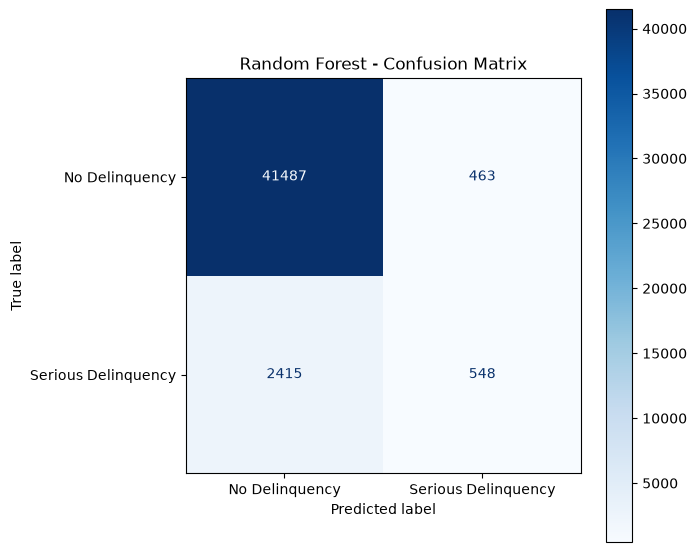

In [25]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "No Delinquency",
        "Serious Delinquency"
    ]
)

fig, ax = plt.subplots(figsize=(7, 6))

disp.plot(
    cmap="Blues",
    ax=ax,
    values_format="d"
)

plt.title("Random Forest - Confusion Matrix")

plt.tight_layout()
plt.show()

## 26.  تابع ارزیابی و ثبت مدل پایه 

In [26]:
results = []

def evaluate_model(name, model, X_te=X_test, y_te=y_test):
    pred = model.predict(X_te)
    row = {
        "Model": name,
        "Accuracy": accuracy_score(y_te, pred),
        "Precision(1)": precision_score(y_te, pred, zero_division=0),
        "Recall(1)": recall_score(y_te, pred, zero_division=0),
        "F1(1)": f1_score(y_te, pred, zero_division=0),
    }
    if hasattr(model, "predict_proba"):
        row["ROC-AUC"] = roc_auc_score(y_te, model.predict_proba(X_te)[:, 1])
    results.append(row)
    return row

# مدل پایه‌ای که قبلاً آموزش دادیم
evaluate_model("RF Baseline", rf_model)
pd.DataFrame(results)

,Model,Accuracy,Precision(1),Recall(1),F1(1),ROC-AUC
0,RF Baseline,0.935921,0.542038,0.184948,0.275793,0.832375


## 27. روش اول: متعادل‌سازی داده با SMOTENC (C-1)

In [27]:
cat_cols = [
    "SEX", "EDUCATION",
    "MonthlyIncome_missing", "NumberOfDependents_missing",
    "Has90DaysLate", "WorstDelayStatus"
]
cat_idx = [X_train.columns.get_loc(c) for c in cat_cols]

smote = SMOTENC(categorical_features=cat_idx, random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

print("Before:", y_train.value_counts().to_dict())
print("After :", y_train_sm.value_counts().to_dict())

rf_smote = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_smote.fit(X_train_sm, y_train_sm)

print(evaluate_model("RF + SMOTENC", rf_smote))
print(classification_report(y_test, rf_smote.predict(X_test),
      target_names=["No Delinquency", "Serious Delinquency"]))

Before: {0: 97882, 1: 6915}
After : {0: 97882, 1: 97882}
{'Model': 'RF + SMOTENC', 'Accuracy': 0.9223610090619643, 'Precision(1)': 0.39384116693679094, 'Recall(1)': 0.32804589942625717, 'F1(1)': 0.357945129810348, 'ROC-AUC': 0.8251273493467505}
                     precision    recall  f1-score   support

     No Delinquency       0.95      0.96      0.96     41950
Serious Delinquency       0.39      0.33      0.36      2963

           accuracy                           0.92     44913
          macro avg       0.67      0.65      0.66     44913
       weighted avg       0.92      0.92      0.92     44913



## 28. روش دوم: حذف داده‌های پرت از مجموعه آموزش 

In [28]:
outlier_cols = [
    "RevolvingUtilizationOfUnsecuredLines", "DebtRatio", "MonthlyIncome",
    "NumberOfOpenCreditLinesAndLoans", "NumberRealEstateLoansOrLines"
]

# آستانه‌ها فقط از Train محاسبه می‌شوند
upper = X_train[outlier_cols].quantile(0.99)

mask = (X_train[outlier_cols] <= upper).all(axis=1)
X_train_clean = X_train[mask]
y_train_clean = y_train[mask]

print("Train before:", X_train.shape[0], "| after:", X_train_clean.shape[0])
print("Delinquent ratio after:", round(y_train_clean.mean() * 100, 2), "%")

rf_clean = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_clean.fit(X_train_clean, y_train_clean)

print(evaluate_model("RF + Outlier Removal", rf_clean))

Train before: 104797 | after: 100030
Delinquent ratio after: 6.2 %
{'Model': 'RF + Outlier Removal', 'Accuracy': 0.935208068933271, 'Precision(1)': 0.5254562920268973, 'Recall(1)': 0.18461019237259535, 'F1(1)': 0.27322677322677325, 'ROC-AUC': 0.8351261948617776}




با حذف مقادیر بالاتر از صدک ۹۹ در ستون‌های پیوسته، تعداد داده‌های Train از ۱۰۴٬۷۹۷ به ۱۰۰٬۰۳۰ رسید و نسبت بدحساب‌ها ۶.۲٪ ماند.
Recall (۰.۱۸۵) و F1 (۰.۲۷۳) تقریباً تغییری نکردند، فقط ROC-AUC اندکی بهتر شد (۰.۸۳۵۱). حذف پرت‌ها تنهایی مشکل شناسایی بدحساب‌ها را حل نمی‌کند.

## 29. روش سوم: امتحان مدل‌های طبقه‌بندی دیگر 

In [29]:
models = {
    "ExtraTrees": ExtraTreesClassifier(
        n_estimators=200, class_weight="balanced", random_state=42, n_jobs=-1),
    "HistGradientBoosting": HistGradientBoostingClassifier(
        class_weight="balanced", random_state=42),
    "RF (balanced)": RandomForestClassifier(
        n_estimators=200, class_weight="balanced", random_state=42, n_jobs=-1),
}

fitted = {}
for name, m in models.items():
    m.fit(X_train_clean, y_train_clean)
    fitted[name] = m
    evaluate_model(name, m)

pd.DataFrame(results).sort_values("F1(1)", ascending=False).round(4)

,Model,Accuracy,Precision(1),Recall(1),F1(1),ROC-AUC
5,RF (balanced),0.9266,0.4296,0.3419,0.3808,0.8392
1,RF + SMOTENC,0.9224,0.3938,0.3280,0.3579,0.8251
4,HistGradientBoosting,0.7893,0.2051,0.7627,0.3233,0.8552
0,RF Baseline,0.9359,0.5420,0.1849,0.2758,0.8324
2,RF + Outlier Removal,0.9352,0.5255,0.1846,0.2732,0.8351
3,ExtraTrees,0.9353,0.5284,0.1728,0.2604,0.8271




مدل RF با class_weight=balanced بهترین F1 را دارد (۰.۳۸۰۸) با Recall برابر ۰.۳۴۱۹ و Precision برابر ۰.۴۲۹۶. HistGradientBoosting بیشترین Recall را دارد (۰.۷۶۲۷) و بهترین ROC-AUC را (۰.۸۵۵۲)، اما Precision آن فقط ۰.۲۰۵۱ است.
مدل ExtraTrees عملکرد ضعیف‌تری داشت (F1 برابر ۰.۲۶۰۴). انتخاب بین RF و HGB بسته به اهمیت Recall یا Precision در کاربرد واقعی است.

## 30. روش چهارم: تنظیم هایپرپارامتر با RandomizedSearchCV

In [30]:
param_dist = {
    "learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
    "max_iter": [100, 200, 300, 500],
    "max_depth": [None, 3, 5, 7, 10],
    "max_leaf_nodes": [15, 31, 63],
    "min_samples_leaf": [20, 50, 100],
    "l2_regularization": [0.0, 0.1, 1.0, 10.0],
}

search = RandomizedSearchCV(
    HistGradientBoostingClassifier(class_weight="balanced", random_state=42),
    param_distributions=param_dist,
    n_iter=10,
    scoring="f1",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    n_jobs=-1,
    random_state=42,
    verbose=1
)
search.fit(X_train_clean, y_train_clean)

print("Best params:", search.best_params_)
print("Best CV F1 :", round(search.best_score_, 4))

best_model = search.best_estimator_
print(evaluate_model("HGB Tuned", best_model))

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best params: {'min_samples_leaf': 50, 'max_leaf_nodes': 63, 'max_iter': 500, 'max_depth': None, 'learning_rate': 0.05, 'l2_regularization': 0.1}
Best CV F1 : 0.3278
{'Model': 'HGB Tuned', 'Accuracy': 0.7937790840068577, 'Precision(1)': 0.20808230605246084, 'Recall(1)': 0.7576780290246372, 'F1(1)': 0.3264979639325189, 'ROC-AUC': 0.853327092946499}




مدل HGB با بهترین پارامترها (learning_rate=0.05، max_iter=500، max_leaf_nodes=63، min_samples_leaf=50، l2_regularization=0.1) به F1 برابر ۰.۳۲۶۵ و Recall برابر ۰.۷۵۷۷ رسید.
بهبود نسبت به HGB پیش‌فرض (F1 برابر ۰.۳۲۳۳) ناچیز است و از RF متعادل‌شده (F1 برابر ۰.۳۸۰۸) هم پایین‌تر مانده است.

In [32]:
rf_param_dist = {
    "n_estimators": [200, 300, 500],
    "max_depth": [None, 10, 15, 20, 30],
    "min_samples_leaf": [1, 2, 5, 10, 20],
    "min_samples_split": [2, 5, 10],
    "max_features": ["sqrt", "log2", 0.5],
    "class_weight": ["balanced", "balanced_subsample"],
}

rf_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    param_distributions=rf_param_dist,
    n_iter=6,
    scoring="f1",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    n_jobs=1,          # خود RF با n_jobs=-1 موازی است
    random_state=42,
    verbose=1
)
rf_search.fit(X_train_clean, y_train_clean)

print("Best params:", rf_search.best_params_)
print("Best CV F1 :", round(rf_search.best_score_, 4))

rf_tuned = rf_search.best_estimator_
print(evaluate_model("RF Tuned", rf_tuned))

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best params: {'n_estimators': 300, 'min_samples_split': 10, 'min_samples_leaf': 10, 'max_features': 'log2', 'max_depth': 30, 'class_weight': 'balanced_subsample'}
Best CV F1 : 0.409
{'Model': 'RF Tuned', 'Accuracy': 0.8896533297708904, 'Precision(1)': 0.3142590866728798, 'Recall(1)': 0.569017887276409, 'F1(1)': 0.4048991354466859, 'ROC-AUC': 0.8517545798257975}


,Model,Accuracy,Precision(1),Recall(1),F1(1),ROC-AUC
7,RF Tuned,0.8897,0.3143,0.5690,0.4049,0.8518
5,RF (balanced),0.9266,0.4296,0.3419,0.3808,0.8392
1,RF + SMOTENC,0.9224,0.3938,0.3280,0.3579,0.8251
6,HGB Tuned,0.7938,0.2081,0.7577,0.3265,0.8533
4,HistGradientBoosting,0.7893,0.2051,0.7627,0.3233,0.8552
0,RF Baseline,0.9359,0.5420,0.1849,0.2758,0.8324
2,RF + Outlier Removal,0.9352,0.5255,0.1846,0.2732,0.8351
3,ExtraTrees,0.9353,0.5284,0.1728,0.2604,0.8271


Best model: RF Tuned
                     precision    recall  f1-score   support

     No Delinquency       0.97      0.91      0.94     41950
Serious Delinquency       0.31      0.57      0.40      2963

           accuracy                           0.89     44913
          macro avg       0.64      0.74      0.67     44913
       weighted avg       0.92      0.89      0.90     44913



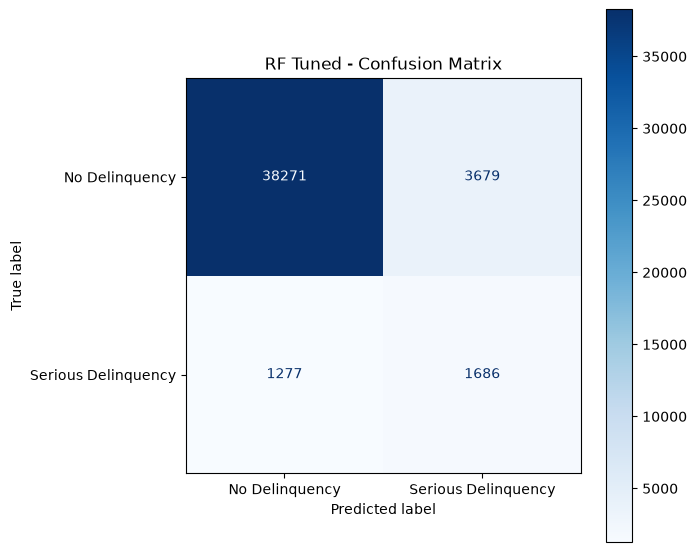

Best hyperparameters: {'n_estimators': 300, 'min_samples_split': 10, 'min_samples_leaf': 10, 'max_features': 'log2', 'max_depth': 30, 'class_weight': 'balanced_subsample'}


In [33]:
final_table = pd.DataFrame(results).sort_values("F1(1)", ascending=False).round(4)
display(final_table)

best_name = final_table.iloc[0]["Model"]
print("Best model:", best_name)

all_models = {**fitted, "HGB Tuned": best_model, "RF Tuned": rf_tuned,
              "RF + SMOTENC": rf_smote, "RF + Outlier Removal": rf_clean,
              "RF Baseline": rf_model}
final_model = all_models[best_name]
y_pred_final = final_model.predict(X_test)

print(classification_report(y_test, y_pred_final,
      target_names=["No Delinquency", "Serious Delinquency"]))

cm = confusion_matrix(y_test, y_pred_final)
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=["No Delinquency", "Serious Delinquency"]).plot(
    cmap="Blues", ax=ax, values_format="d")
plt.title(f"{best_name} - Confusion Matrix")
plt.tight_layout()
plt.show()

if best_name == "RF Tuned":
    print("Best hyperparameters:", rf_search.best_params_)
elif best_name == "HGB Tuned":
    print("Best hyperparameters:", search.best_params_)

## 32. نتیجه‌گیری نهایی

چون داده نامتوازن است (حدود ۶.۶٪ بدحساب)، Accuracy معیار مناسبی نیست و مدل‌ها بر اساس **F1 و Recall کلاس بدحساب** مقایسه شدند.

- **بهترین مدل بر اساس F1:** Random Forest تنظیم‌شده (F1 برابر ۰.۴۰۴۹)
- **بهترین مدل بر اساس Recall:** HistGradientBoosting (Recall برابر ۰.۷۶۲۷)، ولی Precision آن خیلی پایین است.
- **بهترین مدل بر اساس Accuracy و Precision:** مدل پایه RF، اما Recall آن فقط ۰.۱۸ است و بیشتر بدحساب‌ها را نمی‌شناسد.

**مدل نهایی:** RandomForestClassifier با n_estimators=300، max_depth=30، min_samples_split=10، min_samples_leaf=10، max_features='log2' و class_weight='balanced_subsample'. این مدل بهترین تعادل بین Recall و Precision را دارد و Recall آن (۰.۵۷) حدود سه برابر مدل پایه است، به قیمت افت Accuracy از ۹۳.۶٪ به ۸۹٪.